# Phân tích và dự đoán SOH — SDU 2025
Nguyễn Văn Duy · 2311553949

Nguồn: https://doi.org/10.5281/zenodo.14859405 · CC BY 4.0. Bộ chọn 10 triệu điểm đo, 86 pin, 20.823 chu kỳ. Mỗi mẫu huấn luyện là một chu kỳ, không phải một điểm cảm biến.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT/'src'))
from battery_soh.features import FEATURES
data = pd.read_csv(ROOT/'reports/features.csv')
json.loads((ROOT/'reports/dataset_summary.json').read_text())

{'dataset': 'SDU',
 'source': 'https://zenodo.org/records/14859405',
 'source_doi': '10.5281/zenodo.14859405',
 'original_year': 2025,
 'battery_count': 86,
 'all_measurement_rows': 10000000,
 'measurement_rows': 10000000,
 'feature_rows': 20823,
 'discharge_cycles': 20823,
 'nominal_capacity_ah': 2.4,
 'window_seconds': 120,
 'features': ['phase_code',
  'cycle',
  'voltage_mean',
  'voltage_min',
  'voltage_max',
  'voltage_std',
  'voltage_slope',
  'current_mean',
  'current_std',
  'temperature_mean',
  'temperature_max',
  'temperature_slope'],
 'missing_values': 0,
 'duplicates_removed': 0,
 'invalid_rows_removed': 0,
 'excluded_cycles': 0,
 'source_parent_rows': 30929675,
 'source_original_rows': 145112317,
 'suspected_points': 25,
 'suspected_points_in_window': 0,
 'source_backward_steps': 23,
 'phases': {'primary': 'Sử dụng ban đầu', 'second_life': 'Tái sử dụng'},
 'country': 'China; laboratory cells, not Vietnam vehicle packs'}

## 1. Kiểm tra bảng chu kỳ
Khóa gồm mã pin vật lý, giai đoạn và chu kỳ. Dung lượng tham chiếu là 2,4 Ah. SOH trên 100% được giữ nguyên.

In [2]:
assert len(data) == 20823 and data.battery.nunique() == 86
assert not data.duplicated(['battery','phase','cycle']).any()
assert np.isfinite(data[FEATURES].to_numpy()).all()
assert np.allclose(data.soh_pct, data.capacity_ah/2.4*100)
data.groupby('phase').agg(pins=('battery','nunique'), cycles=('cycle','size'), min_soh=('soh_pct','min'), max_soh=('soh_pct','max'))

,pins,cycles,min_soh,max_soh
phase,,,,
primary,86,12661,78.32750,102.568625
second_life,86,8162,48.76375,83.344042


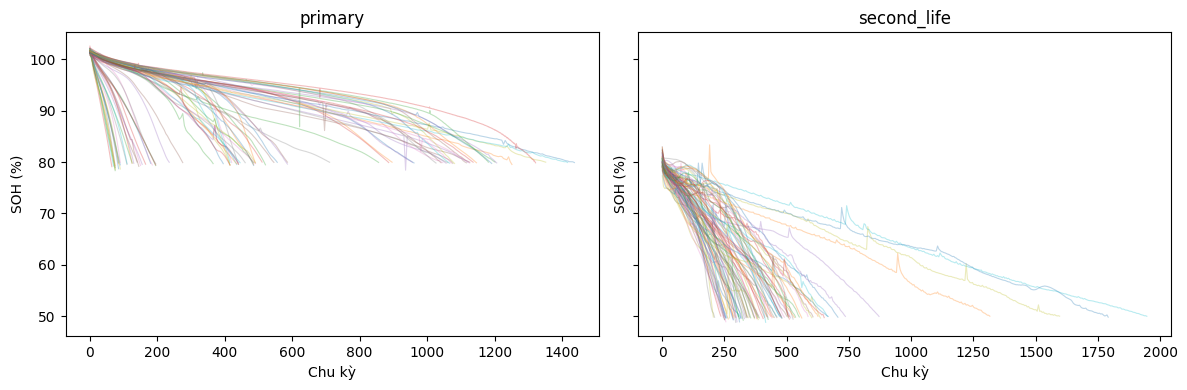

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12,4), sharey=True)
for ax, (phase, group) in zip(axes, data.groupby('phase')):
    for battery, part in group.groupby('battery'):
        part = part.sort_values('cycle')
        ax.plot(part.cycle, part.soh_pct, alpha=.3, linewidth=.8)
    ax.set(title=phase, xlabel='Chu kỳ', ylabel='SOH (%)')
fig.tight_layout()
plt.show()

## 2. Đặc trưng đầu xả
Chỉ lấy 120 giây đầu. Nhãn, dung lượng cuối chu kỳ, tổng số điểm và thời gian toàn chu kỳ không thuộc đầu vào. Tương quan mô tả không chứng minh quan hệ nhân quả; không chọn đặc trưng theo tập kiểm thử.

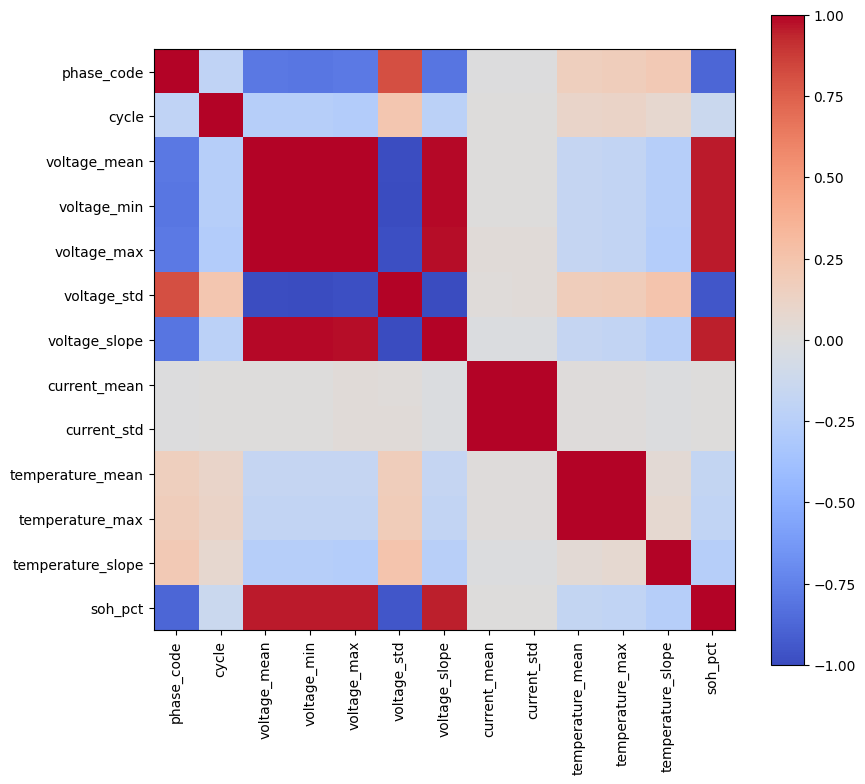

In [4]:
corr = data[FEATURES + ['soh_pct']].corr()
fig, ax = plt.subplots(figsize=(9,8))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()

## 3. Phân hoạch pin
Cùng 5 vòng GroupKFold cho các mô hình. Cả hai giai đoạn của một pin nằm trong cùng phía; bộ chuẩn hóa chỉ học trên train.

In [5]:
split = pd.read_csv(ROOT/'reports/split_assignments.csv')
assert split.battery.nunique() == len(split) == 86
for fold in range(1,6):
    test_pins = set(split.loc[split.test_fold == fold, 'battery'])
    train_pins = set(split.loc[split.test_fold != fold, 'battery'])
    assert train_pins.isdisjoint(test_pins)
split.groupby('test_fold').size().rename('Số pin kiểm thử')

test_fold
1    18
2    17
3    17
4    17
5    17
Name: Số pin kiểm thử, dtype: int64

## 4. So sánh mô hình
Ridge, Random Forest, LightGBM và GRU; mốc trung bình SOH làm đối chứng. GRU dùng chuỗi V/I/T 25 vị trí trong cửa sổ đầu xả cùng số chu kỳ và giai đoạn, khác biểu diễn của mô hình bảng. MAE/RMSE tính bằng điểm phần trăm SOH, chỉ số chính lấy trung bình theo pin.

,model,mae,rmse,r2
0,Mean baseline,13.245927,15.248865,-0.280886
1,Ridge,2.581804,3.298624,0.933199
2,Random Forest,1.618896,2.157199,0.970485
3,LightGBM,1.734383,2.270027,0.967705
4,GRU,2.141391,2.718008,0.952783


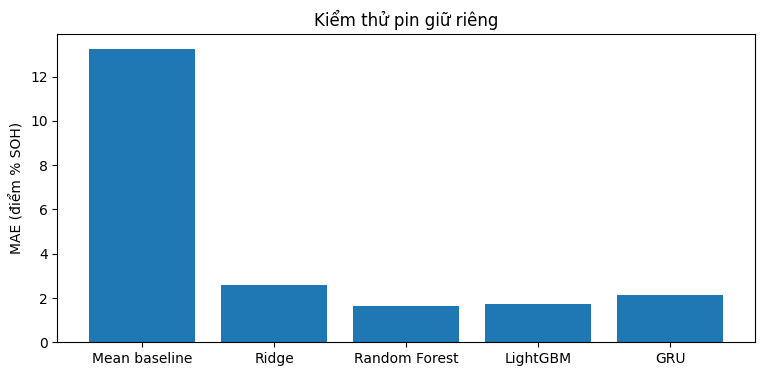

In [6]:
metrics = pd.read_csv(ROOT/'reports/metrics_summary.csv')
display(metrics)
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(metrics.model, metrics.mae)
ax.set(ylabel='MAE (điểm % SOH)', title='Kiểm thử pin giữ riêng')
plt.show()

In [7]:
pd.read_csv(ROOT/'reports/metrics_by_phase.csv')

,model,phase,n_test,mae,rmse,r2
0,GRU,primary,12661,0.979178,1.358186,0.941151
1,GRU,second_life,8162,2.900545,3.555006,0.831702
2,LightGBM,primary,12661,0.877913,1.175269,0.955935
3,LightGBM,second_life,8162,2.348679,3.049971,0.876123
4,Mean baseline,primary,12661,10.595101,11.847524,-3.477922
5,Mean baseline,second_life,8162,16.156094,18.343457,-3.480855
6,Random Forest,primary,12661,0.841284,1.189183,0.954885
7,Random Forest,second_life,8162,2.181721,2.950735,0.884053
8,Ridge,primary,12661,1.464140,2.164829,0.850491
9,Ridge,second_life,8162,3.168026,4.099312,0.776220


## 5. Phân tích sai số
Sai số dương nghĩa là dự đoán cao hơn SOH thực tế. Kiểm tra riêng hai giai đoạn và pin để tránh kết luận từ một điểm trung bình.

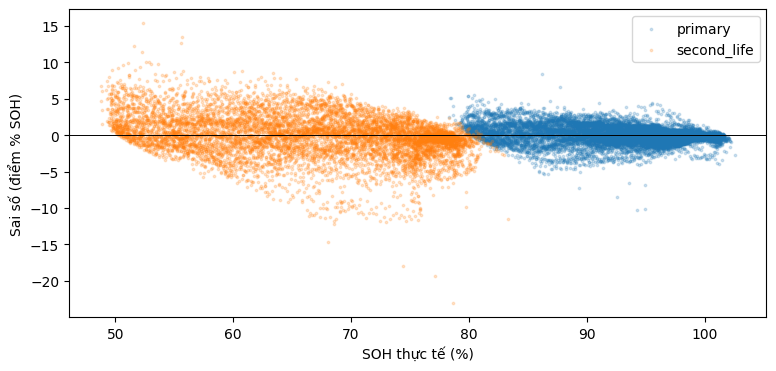

,mean,std,min,max
phase,,,,
primary,0.044778,1.188386,-10.227609,8.368171
second_life,-0.043447,2.950596,-23.057982,15.399169


In [8]:
pred = pd.read_csv(ROOT/'reports/predictions.csv')
rf = pred[pred.model == 'Random Forest'].copy()
rf['error'] = rf.predicted_soh - rf.actual_soh
fig, ax = plt.subplots(figsize=(9,4))
for phase, part in rf.groupby('phase'):
    ax.scatter(part.actual_soh, part.error, s=3, alpha=.2, label=phase)
ax.axhline(0, color='black', linewidth=.7)
ax.set(xlabel='SOH thực tế (%)', ylabel='Sai số (điểm % SOH)')
ax.legend()
plt.show()
rf.groupby('phase').error.agg(['mean','std','min','max'])

## 6. Kiểm tra bổ sung
Bỏ nhóm đặc trưng dùng cùng phân hoạch và tham số RF. Kiểm thử 70/30 theo thời gian trong từng pin và giai đoạn trả lời bài toán khác với pin mới; không trộn điểm.

In [9]:
display(pd.read_csv(ROOT/'reports/ablation_summary.csv'))
temporal = pd.read_csv(ROOT/'reports/temporal_metrics.csv')
assert (temporal.last_train_cycle < temporal.first_test_cycle).all()
temporal.groupby('model')[['mae','rmse']].mean()

,configuration,mae,rmse
0,Without cycle,1.971891,2.480338
1,Without phase,1.639505,2.174690
2,Voltage only,2.183738,2.710261
3,Full features,1.618896,2.157199


,mae,rmse
model,,
Last known SOH,5.528668,6.492530
Random Forest,4.962546,5.600327


## 7. Chất lượng và giới hạn
25 điểm nghi vấn được giữ để xem xét, không nằm trong cửa sổ 120 giây đầu. Bộ chọn giữ đủ các chu kỳ xả tham chiếu, không gồm mọi trạng thái trong nguồn. Dữ liệu phòng thí nghiệm chưa đại diện cho bộ pin xe thực tế tại Việt Nam.

In [10]:
json.loads((ROOT/'reports/dataset_check.json').read_text())

{'status': 'passed',
 'dataset': 'SDU',
 'measurement_rows': 10000000,
 'independent_batteries': 86,
 'feature_samples': 20823,
 'missing_values': 0,
 'duplicate_measurement_keys': 0,
 'nominal_capacity_ah': 2.4,
 'source_doi': '10.5281/zenodo.14859405',
 'suspected_points': 25,
 'suspected_points_in_window': 0,
 'scope': 'All prepared Parquet batches checked; source-byte hashes and all window features checked during preparation. Suspect points retained.'}